# Optimize spring constants, with shapes held fixed

This tutorial changes **which numbers the outer optimizer controls**. We first fit three axial spring constants, shared by columns of hinges. Then we fit a single common axial constant and a common **bending** constant. The scalar energy and equilibrium solver are reused throughout.

The data are synthetic individual bottom-support forces at several prescribed strains. Replace them with your own measurements using the same ordering, units, and sign convention. Fitting only one summed force curve generally does not identify many independent spring constants.

Run after installing `python -m pip install -e ".[notebook]"` from the repository root. The corresponding script is [optimize_spring_constants.py](optimize_spring_constants.py).

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from rotating_polygons import (
    square_grid,
    compression_boundary,
    initialize,
    MechanicalParameters,
    make_parameterized_potential,
    QuasistaticOptions,
    make_quasistatic_solver,
    reaction_forces,
    minimize_design,
)

jax.config.update("jax_enable_x64", True)  # Enable precision before creating arrays.
%matplotlib inline

## 1. Geometry and supports stay fixed

The slight skew makes rotational response visible. These offsets are **constants**, not optimizer entries. Unlike shape optimization, the reference geometry needs to be initialized only once.

In [2]:
geometry = square_grid(3, 3, hinge_gap=0.2)  # Nine polygons and twelve connecting hinges.
boundary = compression_boundary(geometry)  # Fixed bottom grip and descending top grip.
offsets = jnp.zeros((4, 2)).at[1, 0].set(0.08).at[0, 1].set(0.04)  # Fixed local vertex offsets.
vertices = geometry.vertices + jnp.tile(offsets, (geometry.n_polygons, 1))
reference = initialize(geometry, vertices)  # Rest lengths/angles do not change in this tutorial.
bottom_ids = np.flatnonzero(np.isclose(np.asarray(geometry.reference_state[:, 1]), 0.0))
strains = jnp.linspace(0.0, 0.03, 5)  # Five equilibrium loading steps.

## 2. Group the springs you want to optimize

Each row of `geometry.bonds` contains two **vertex IDs**. Use `vertex_polygons` to find their owners, then their centers to distinguish horizontal and vertical connections. The six vertical hinges form three groups (columns 0, 1, 2). Horizontal hinges keep axial stiffness 1.

A group map controls the number of independent variables; the number of simulated hinges does not change.

In [3]:
owners = geometry.vertex_polygons[geometry.bonds]  # Shape (n_bonds, 2): polygon owners.
centers = geometry.reference_state[owners, :2]  # Shape (n_bonds, 2, 2): endpoint centers.
vertical = jnp.abs(centers[:, 0, 1] - centers[:, 1, 1]) > 0.5  # True for vertical bonds.
column_ids = jnp.rint(centers[:, 0, 0]).astype(int)  # Lattice x coordinate gives column ID.
print("Vertical bond IDs:", np.flatnonzero(np.asarray(vertical)))
print("Their stiffness groups:", np.asarray(column_ids)[np.asarray(vertical)])

Vertical bond IDs: [1 3 4 6 8 9]
Their stiffness groups: [0 1 2 0 1 2]


## 3. Map design variables to physical stiffnesses

Optimize `z = log(k)` and evaluate `k = exp(z)`, so stiffness stays positive. `MechanicalParameters` is a JAX-compatible container: geometry and candidate coefficients travel **explicitly** through the solver. This is necessary for implicit differentiation to see their influence on equilibrium.

`PotentialParameters` with `make_potential` remains appropriate for fixed coefficients, as in tutorial 01. Do not rebuild a fixed-coefficient potential or solver inside a differentiated objective.

In [4]:
def column_material(log_stiffness):
    stiffness = jnp.exp(
        log_stiffness
    )  # Three positive physical constants from three log variables.
    axial = jnp.where(vertical, stiffness[column_ids], 1.0)  # Expand groups; keep horizontal k=1.
    return MechanicalParameters(
        reference=reference,  # Same reference geometry for every material candidate.
        stretching=axial,  # One axial value per bond, generated from THREE design variables.
        shearing=0.1,  # Fixed coefficient: not in the optimizer vector.
        bending=0.02,  # Fixed here; optimized separately below.
        contact=40.0,  # Fixed local contact penalty.
    )


initial_log_stiffness = jnp.zeros(3)  # exp(0)=1: start every column at unit axial stiffness.
physical_bounds = (0.4, 2.0)  # Allowed range for each active axial spring constant.
log_bounds = [(np.log(physical_bounds[0]), np.log(physical_bounds[1]))] * 3

## 4. Build one parameterized potential and solver

The first argument of `simulate` is now a complete `MechanicalParameters` object. Always pass that **same object** when computing reactions; measuring with outdated coefficients would give the wrong objective and gradient.

In [5]:
potential = make_parameterized_potential(geometry, model="finite_hinge")  # E(q, model_parameters).
solver_options = QuasistaticOptions(
    method="bfgs",
    tolerance=1e-9,
    max_iterations=500,  # INNER equilibrium settings.
)
simulate = make_quasistatic_solver(geometry, boundary, potential, solver_options)  # Construct once.


def support_forces(states, material):
    reactions = reaction_forces(potential, states, material)  # dE/dq at each state.
    return reactions[:, bottom_ids, 1]  # y-reactions on the three bottom supports: (steps, 3).

## 5. Define a reusable force-matching objective

The loss below is written out rather than hidden in a helper. `material_map` decides what the parameters mean; `target_forces` decides the desired response. The derivative includes both the **direct** coefficient dependence of force and the **indirect** effect through equilibrium coordinates.

`check_convergence()` is used outside differentiation. Inside the objective we instead use the JAX convergence flags so failed trajectories cannot produce accepted designs.

In [6]:
def make_force_objective(material_map, target_forces):
    scale = float(jnp.max(jnp.abs(target_forces)))  # Fixed normalization, evaluated outside JIT.
    if scale <= 0:
        raise ValueError("Use a nonzero calibration load or supply another force scale")

    def objective(parameters):
        material = material_map(parameters)  # Convert optimizer coordinates to physical constants.
        solution = simulate(material, strains)  # Re-equilibrate using the candidate constants.
        predicted = support_forces(solution.states, material)  # Same coefficients as the solve.
        error = jnp.mean(((predicted - target_forces) / scale) ** 2)  # Dimensionless scalar MSE.
        return jnp.where(jnp.all(solution.converged), error, jnp.inf)  # Reject failed equilibria.

    return objective

## 6. Fit the three column constants

Synthetic targets use known constants solely to generate observations. The optimizer sees target forces, bounds, and its initial variables. It never receives those known constants as an initial guess or constraint.

In [7]:
target_constants = jnp.array([0.7, 1.1, 1.5])  # Used only to synthesize this reproducible dataset.
target_material = column_material(jnp.log(target_constants))
target_solution = simulate(target_material, strains).check_convergence()
target_forces = support_forces(target_solution.states, target_material)  # Replace with your data.
column_loss = make_force_objective(column_material, target_forces)

value, gradient = jax.jit(jax.value_and_grad(column_loss))(initial_log_stiffness)
print("Initial loss:", float(value))
print("d(loss)/d(log k):", np.asarray(gradient))  # These derivatives are in LOG coordinates.

column_result = minimize_design(
    column_loss,
    initial_log_stiffness,
    bounds=log_bounds,  # Bounds also use LOG coordinates.
    maxiter=60,
    tol=1e-10,  # OUTER design settings, distinct from equilibrium settings.
)
if not column_result.success:
    raise RuntimeError(column_result.message)
fitted_constants = jnp.exp(column_result.parameters)  # Convert optimizer result back to physical k.
fitted_material = column_material(column_result.parameters)
fitted_solution = simulate(fitted_material, strains).check_convergence()
fitted_forces = support_forces(fitted_solution.states, fitted_material)
print("Known constants:", np.asarray(target_constants))
print("Fitted constants:", np.asarray(fitted_constants))
print(f"Normalized force MSE: {column_result.initial_loss:.6g} -> {column_result.fun:.6g}")

Initial loss: 0.007631035620669859
d(loss)/d(log k): [ 0.01219025 -0.00562009 -0.02564591]


Known constants: [0.7 1.1 1.5]
Fitted constants: [0.70000084 1.10000286 1.4999985 ]
Normalized force MSE: 0.00763104 -> 3.18955e-13


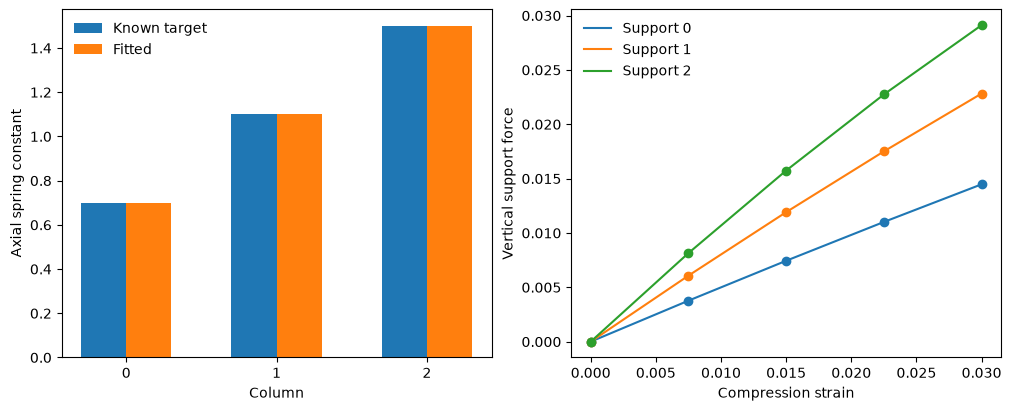

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
indices = np.arange(3)
axes[0].bar(indices - 0.15, target_constants, 0.3, label="Known target")
axes[0].bar(indices + 0.15, fitted_constants, 0.3, label="Fitted")
axes[0].set(xlabel="Column", ylabel="Axial spring constant", xticks=indices)
axes[0].legend(frameon=False)
for column in range(3):
    axes[1].plot(strains, target_forces[:, column], "o", color=f"C{column}")
    axes[1].plot(strains, fitted_forces[:, column], color=f"C{column}", label=f"Support {column}")
axes[1].set(xlabel="Compression strain", ylabel="Vertical support force")
axes[1].legend(frameon=False)
plt.show()

## 7. Change the active parameter: one axial constant, then one bending constant

The solver and force objective need no changes. Replace the material map, the initial vector, and its bounds. A scalar coefficient broadcasts to every bond. For the bending case, axial stiffness is held fixed at 1 and the only active variable is `log(k_theta)`.

The small fixed shape skew lets bending influence equilibrium. In a perfectly symmetric unrotated configuration, bending stiffness can be poorly observable from axial forces.

In [9]:
def uniform_axial_material(log_stiffness):
    return MechanicalParameters(
        reference,
        stretching=jnp.exp(log_stiffness[0]),  # ONE common axial coefficient.
        shearing=0.1,
        bending=0.02,
        contact=40.0,  # Everything else is fixed.
    )


def uniform_bending_material(log_stiffness):
    return MechanicalParameters(
        reference,
        stretching=1.0,
        shearing=0.1,  # Axial and shear coefficients are fixed.
        bending=jnp.exp(log_stiffness[0]),
        contact=40.0,  # ONE active rotational coefficient.
    )


cases = [
    ("Common axial k", uniform_axial_material, 1.0, 1.35, (0.4, 2.0)),
    ("Common bending k", uniform_bending_material, 0.02, 0.035, (0.005, 0.1)),
]
material_results = {}
for name, material_map, initial_k, known_k, (lower, upper) in cases:
    target = material_map(jnp.log(jnp.array([known_k])))  # Synthetic observation generator.
    target_states = simulate(target, strains).check_convergence().states
    observations = support_forces(target_states, target)
    objective = make_force_objective(material_map, observations)  # Same loss implementation.
    result = minimize_design(
        objective,
        jnp.log(jnp.array([initial_k])),  # ONE optimization variable now.
        bounds=[(np.log(lower), np.log(upper))],  # ONE corresponding bound pair.
        maxiter=60,
        tol=1e-10,
    )
    if not result.success:
        raise RuntimeError(result.message)
    simulate(
        material_map(result.parameters), strains
    ).check_convergence()  # Check final equilibria.
    material_results[name] = result
    print(f"{name}: target={known_k:g}, fitted={float(jnp.exp(result.parameters[0])):.8g}")
    print(f"  loss {result.initial_loss:.6g} -> {result.fun:.6g}")

Common axial k: target=1.35, fitted=1.3499954
  loss 0.00986569 -> 1.33094e-12


Common bending k: target=0.035, fitted=0.035000149
  loss 0.000174054 -> 1.32724e-14


## 8. Independent constants on every bond

Replace the group indexing with a length-`n_bonds` array to give each hinge its own bending constant. The example below evaluates the model and its derivative. Estimating all these values from one loading history can be underdetermined: use additional load cases/observations, a smaller group map, or a clearly justified regularization term before fitting them.

In [10]:
def independent_bending_material(log_bending):
    return MechanicalParameters(
        reference,
        stretching=1.0,
        shearing=0.1,
        bending=jnp.exp(log_bending),  # Shape (n_bonds,): one rotational stiffness per hinge.
        contact=40.0,
    )


per_bond_initial = jnp.full(geometry.n_bonds, jnp.log(0.02))  # Twelve independent log variables.
per_bond_model = independent_bending_material(per_bond_initial)
per_bond_solution = simulate(per_bond_model, strains).check_convergence()
print("Number of independent bending variables:", per_bond_initial.size)
print("Material coefficient shape:", per_bond_model.bending.shape)
# For fitting: create suitable observations, then use
# objective = make_force_objective(independent_bending_material, observations)
# result = minimize_design(objective, per_bond_initial,
#     bounds=[(np.log(0.005), np.log(0.1))] * geometry.n_bonds, maxiter=100, tol=1e-8)


def total_bottom_load(log_bending):
    material = independent_bending_material(log_bending)
    states = simulate(material, strains).states
    return jnp.sum(support_forces(states, material)[-1])  # Total reaction at the final strain.


sensitivity = jax.jit(jax.grad(total_bottom_load))(per_bond_initial)
print("d(total load)/d(log bending):", np.asarray(sensitivity))
# A zero sensitivity indicates a hinge this particular load case does not excite.

Number of independent bending variables: 12
Material coefficient shape: (12,)


d(total load)/d(log bending): [ 0.00000000e+00  4.12078522e-04  0.00000000e+00  1.62260383e-04
  2.05510723e-05  5.61839249e-05  4.12078522e-04 -6.38550025e-05
  1.62260383e-04  2.05510723e-05  0.00000000e+00  0.00000000e+00]


## 9. Choosing what the optimizer changes

| Design choice | Optimizer coordinates | Material/geometry map |
| --- | --- | --- |
| Shared axial constant | One `log(k_l)` | `stretching=exp(z[0])` |
| Column groups | Three `log(k_l)` values | `stretching=where(vertical, exp(z)[column_ids], 1)` |
| Shared bending constant | One `log(k_theta)` | `bending=exp(z[0])` |
| Independent bending constants | `n_bonds` log values | `bending=exp(z)` |
| Shape plus stiffness | Shape offsets and log constants | Recompute `initialize(geometry, vertices)` inside the material map |

A number in `MechanicalParameters` is fixed unless it is computed from an entry of the optimizer's parameter vector. For joint design, pass a dictionary to `minimize_design` and read its fields in your material map; see the [module guide](../docs/modules.md) for a complete example and the flattening order used for bounds.

[Return to the example guide](README.md).